# Shear mocks for the discrete covariance of $\xi_\pm$ and COSEBIs

Gaussian shear fields on the full sphere (healpy) with the power spectrum of the last
tomographic bin of `input/Cell/Cell_kappakappa.ascii` (used as the E-mode shear power
spectrum, no B-modes), sampled by `N_pos` galaxies at fixed positions inside a survey mask.
Every realisation draws a new shear field and new shape noise; the positions stay the same.
For each realisation

1. the shear at the galaxy positions is read off the healpix map (pixel centres),
2. shape noise with dispersion `shape_noise_scale*sigma_eps` per component is added,
3. $\xi_\pm$ is measured with orpheus in fine logarithmic bins,
4. the COSEBIs are computed from the fine bins with the tabulated filters of
   `input/arbitrary_summary/cosebis/`, exactly as `CovTHETAtoOBS` does for
   `theta_to_obs = True`:
   $E_n/B_n = \sum_i A^\pm_{ni}\,\xi_{\pm,i}$ with $A^\pm_{ni} = \int_{{\rm bin}\,i}{\rm d}\theta\,\theta\,T_{\pm n}(\theta)$
   (`filter_matrix` with bin averaging; the tables already contain the factor 1/2).

The mean over the realisations is compared with the prediction
$E_n = \frac{1}{2\pi}\int{\rm d}\ell\,\ell\,W_n(\ell)\,C_\ell$ (OneCovariance's `_project_signal`),
evaluated with the $C_\ell$ of the healpix map. Outputs (in `output_directory`): one catalogue
(fits, columns `RA`, `DEC` as needed by `catalog_file` in `[covTHETAspace discrete]`) and the
COSEBIs (and fine-binned $\xi_\pm$) of all realisations.

In [1]:
import os
import sys
import time

# levin, orpheus and sklearn each bring a libomp on macOS (see covariance.py)
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'

import healpy as hp
import matplotlib.pyplot as plt
import numpy as np
import orpheus
from astropy.io import fits
from scipy.special import jv

sys.path.insert(0, os.path.abspath('..'))
from onecov.cov_theta_to_obs import (ARCMIN, RealSpaceFilter, filter_matrix,
                                     fine_theta_edges)

## Settings

The runtime per realisation is dominated by `hp.alm2map_spin` (10 s at `nside = 2048`, about
8 times more at 4096) and the exact pair counting of orpheus (about 2.5 s for $10^5$ galaxies
in 1000 deg$^2$, growing as $N_{\rm pos}^2$). The shear is taken at the pixel centres, so the
prediction includes the pixel window, $C_\ell\,w_\ell^2$; with it the mean $\xi_+$ of the mocks
agrees with the prediction to 1 to 3 per cent down to 0.4 pixel sizes (tested at `nside = 2048`).

In [2]:
Cell_file = '../input/Cell/Cell_kappakappa.ascii'
cosebi_directory = '../input/arbitrary_summary/cosebis/'
output_directory = './output/'

# healpix resolution of the shear map and the mask, lmax = 3 nside - 1
nside = 1024
# number of galaxies, at the same positions in all realisations
N_pos = 100000
# ellipticity dispersion per component (last tomographic bin in config.ini),
# the shape noise is shape_noise_scale*sigma_eps (0 for noise-free mocks)
sigma_eps = 0.27
shape_noise_scale = 0
n_realisations = 100
# seed of the mask and the positions, realisation i uses seed + 1 + i
seed = 1234

# range of the COSEBI filter tables (in arcmin), number of modes and of the
# logarithmic xi_pm bins (DEFAULT_FINE_BINS['cosebi'] of CovTHETAtoOBS)
theta_min, theta_max = 0.5, 300.
n_modes = 6
n_fine_bins = 500

# orpheus tree: cells of size tree_resos (in arcmin, 0: exact pairs) are used for
# separations above rmin_pixsize times the cell size. On the sphere the cells bias
# xi_pm low by about 10 per cent wherever they are used (the pair counts are fine),
# so the pairs are counted exactly
rmin_pixsize = 40.
tree_resos = [0]
num_cores = os.cpu_count()

os.makedirs(output_directory, exist_ok=True)
lmax = 3*nside - 1
fine_edges = fine_theta_edges([theta_min, theta_max], n_fine_bins)

## Power spectrum

The last tomographic bin, interpolated log-log onto all integer multipoles up to `lmax` and
extrapolated as a power law beyond the tabulated range.

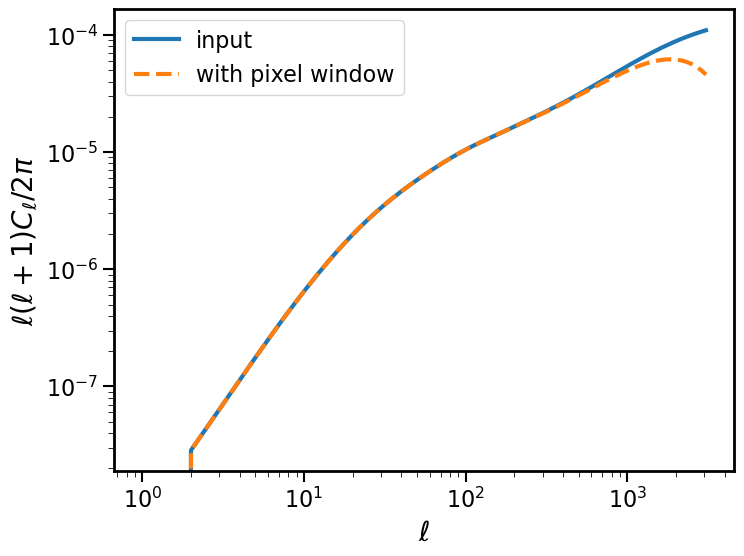

In [3]:
def read_Cell(Cell_file, lmax):
    """
    C_ell of the last tomographic bin (auto-correlation) at ell = 0, ..., lmax
    (zero for ell < 2), log-log interpolated and extrapolated as power laws.
    """
    data = np.loadtxt(Cell_file)
    n_tomo = int(np.max(data[:, 1]))
    data = data[(data[:, 1] == n_tomo) & (data[:, 2] == n_tomo)]
    ln_ell, ln_C = np.log(data[:, 0]), np.log(data[:, 3])
    ell = np.arange(2, lmax + 1)
    ln_C_ell = np.interp(np.log(ell), ln_ell, ln_C)
    for edge, inside in ((0, ell < data[0, 0]), (-1, ell > data[-1, 0])):
        neighbour = 1 if edge == 0 else -2
        slope = (ln_C[edge] - ln_C[neighbour])/(ln_ell[edge] - ln_ell[neighbour])
        ln_C_ell[inside] = ln_C[edge] + slope*(np.log(ell[inside]) - ln_ell[edge])
    return np.concatenate(([0., 0.], np.exp(ln_C_ell)))


Cell = read_Cell(Cell_file, lmax)
# the shear is read off at the pixel centres: the measured spectrum carries the
# pixel window
Cell_observed = Cell*hp.pixwin(nside, lmax=lmax)**2

ell = np.arange(lmax + 1)
plt.loglog(ell, ell*(ell + 1)*Cell/2/np.pi, label='input')
plt.loglog(ell, ell*(ell + 1)*Cell_observed/2/np.pi, '--', label='with pixel window')
plt.xlabel(r'$\ell$')
plt.ylabel(r'$\ell(\ell+1)C_\ell/2\pi$')
plt.legend()
plt.show()

## Survey mask

A field of about 1000 deg$^2$ with wavy edges and a missing corner, cut by star masks
(circular holes with a power-law distribution of radii between 1 and 20 arcmin), a few large
holes (bright stars, nearby galaxies) and satellite trails (great-circle segments of a few
arcmin width).

area: 906.4 deg^2, pixel size: 3.44 arcmin


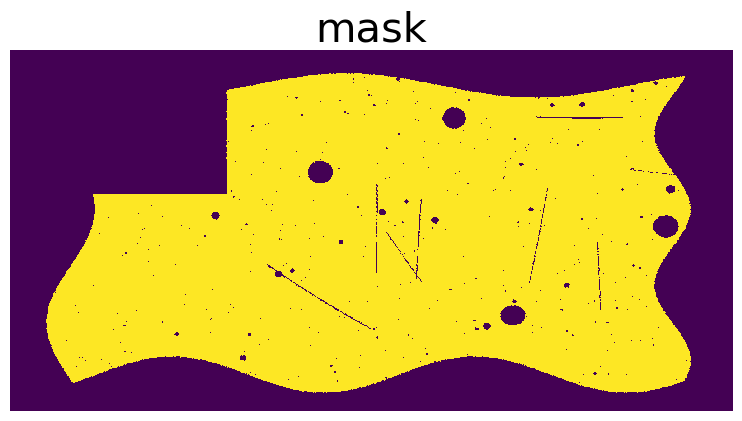

In [4]:
def make_mask(nside, rng):
    """
    Boolean healpix map (ring ordering) of the survey footprint.
    """
    mask = np.zeros(hp.nside2npix(nside), dtype=bool)
    # the field, ra in [15, 65] deg and dec in [-42, -18] deg with wavy edges
    pix = hp.query_strip(nside, np.radians(90 + 18 - 2), np.radians(90 + 42 + 2))
    ra, dec = hp.pix2ang(nside, pix, lonlat=True)
    field = ((ra > 15 + 1.5*np.sin(dec/2)) & (ra < 65 + 2*np.cos(dec/3))
             & (dec > -42 + 1.5*np.sin(ra/4)) & (dec < -18 - np.cos(ra/5 + 1))
             & ~((ra > 52) & (dec > -27)))
    mask[pix[field]] = True
    centres = np.transpose(hp.pix2vec(nside, rng.choice(pix[field], 608)))
    holes, trails = centres[:600], centres[600:]
    # star masks: dN/dr ~ r^-2.5 between 1 and 20 arcmin, and five large holes
    radii = (1. + rng.uniform(size=595)*(20.**-1.5 - 1.))**(-1/1.5)*ARCMIN
    radii = np.concatenate((radii, np.radians(rng.uniform(.3, 1., 5))))
    for centre, radius in zip(holes, radii, strict=True):
        mask[hp.query_disc(nside, centre, radius)] = False
    # satellite trails: great-circle segments, 2 to 6 arcmin wide and 3 to 10 deg long
    for centre in trails:
        normal = np.cross(centre, rng.normal(size=3))
        normal /= np.linalg.norm(normal)
        disc = hp.query_disc(nside, centre, np.radians(rng.uniform(1.5, 5.)))
        width = rng.uniform(2., 6.)*ARCMIN
        distance = np.abs(np.transpose(hp.pix2vec(nside, disc)) @ normal)
        mask[disc[distance < np.sin(width/2)]] = False
    return mask


rng = np.random.default_rng(seed)
mask = make_mask(nside, rng)
area = np.sum(mask)*hp.nside2pixarea(nside, degrees=True)
print('area: %.1f deg^2, pixel size: %.2f arcmin'
      % (area, hp.nside2resol(nside, arcmin=True)))
hp.cartview(mask.astype(float), lonra=[10, 70], latra=[-45, -15], cbar=False,
            title='mask', xsize=1600)
plt.show()

## Galaxy positions

Uniform on the sphere within the mask (rejection sampling in an ra/dec box), the same for all
realisations.

n_gal = 0.031 / arcmin^2


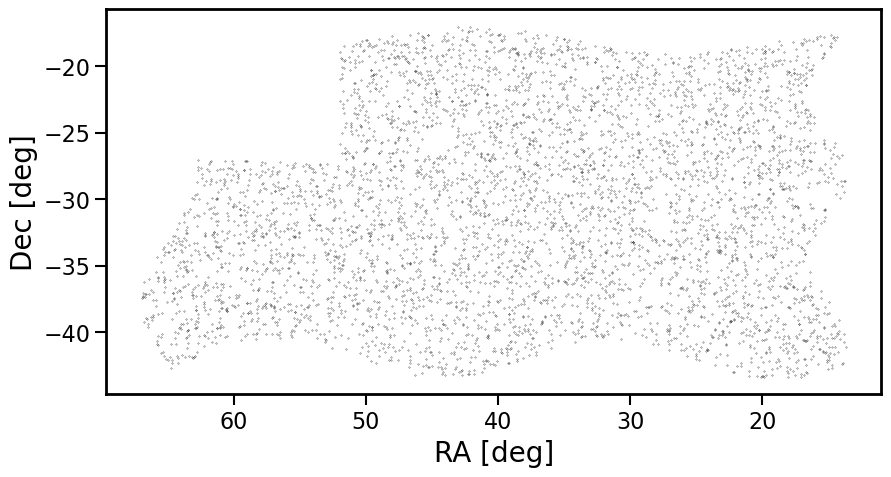

In [5]:
def draw_positions(mask, N_pos, rng):
    """
    N_pos positions (ra, dec in degrees) distributed uniformly within the
    mask, and the pixels of the mask they fall into.
    """
    nside = hp.npix2nside(len(mask))
    ra_mask, dec_mask = hp.pix2ang(nside, np.flatnonzero(mask), lonlat=True)
    margin = hp.nside2resol(nside, arcmin=True)/60.
    ra_range = [np.min(ra_mask) - margin, np.max(ra_mask) + margin]
    dec_range = np.radians([np.min(dec_mask) - margin, np.max(dec_mask) + margin])
    ra, dec = [], []
    while sum(len(chunk) for chunk in ra) < N_pos:
        ra_new = rng.uniform(*ra_range, N_pos)
        dec_new = np.degrees(np.arcsin(rng.uniform(*np.sin(dec_range), N_pos)))
        inside = mask[hp.ang2pix(nside, ra_new, dec_new, lonlat=True)]
        ra.append(ra_new[inside])
        dec.append(dec_new[inside])
    ra, dec = np.concatenate(ra)[:N_pos], np.concatenate(dec)[:N_pos]
    return ra, dec, hp.ang2pix(nside, ra, dec, lonlat=True)


ra, dec, pix = draw_positions(mask, N_pos, rng)
print('n_gal = %.3f / arcmin^2' % (N_pos/area/3600))
plt.figure(figsize=(10, 5))
plt.scatter(ra[::20], dec[::20], s=.05, c='k')
plt.xlabel('RA [deg]')
plt.ylabel('Dec [deg]')
plt.gca().invert_xaxis()
plt.show()

## Inputs for OneCovariance

`config_files/config_discrete.ini` computes the covariance of these mocks: it reads the
catalogue, this spectrum (with the pixel window, up to `lmax`, as `Cmm_file`; OneCovariance
continues it beyond `ell_max` as a power law) and the survey specifications printed below.

In [ ]:
def write_Cell_table(Cell, Cell_file, n_ell=300):
    """
    Cell (ell = 0, ..., lmax) on n_ell logarithmically spaced integer
    multipoles between 2 and lmax in the format of Cmm_file (ell, tomo_i,
    tomo_j, C_ell) for a single tomographic bin.
    """
    ell = np.unique(np.rint(np.geomspace(2, len(Cell) - 1, n_ell)).astype(int))
    ones = np.ones_like(ell)
    np.savetxt(Cell_file, np.column_stack((ell, ones, ones, Cell[ell])),
               fmt=['%i', '%i', '%i', '%.10e'],
               header='ell\ttomo_i\ttomo_j\tCell_kappakappa')


Cmm_file = os.path.join(output_directory, 'Cell_kappakappa_mocks.ascii')
write_Cell_table(Cell_observed, Cmm_file)
print('[covELLspace settings]\nell_max = %i\n' % lmax)
print('[survey specs]\nsurvey_area_lensing_in_deg2 = %.4f\nn_eff_lensing = %.6f'
      % (area, N_pos/area/3600))
print('ellipticity_dispersion = %.4f' % (shape_noise_scale*sigma_eps))

## Shear field, shape noise and measurement

healpy measures the polarisation angle from $e_\theta$ (south) towards $e_\phi$ (east), the
shear in the catalogue is measured from the ra- towards the dec-direction, so
$\gamma = -(Q + {\rm i}U)$ (an overall sign or a parity flip leaves $\xi_\pm$ unchanged).

In [6]:
def shear_realisation(Cell, nside, pix, seed):
    """
    Shear (gamma_1, gamma_2) at the pixels pix of a Gaussian E-mode field
    with power spectrum Cell (ell = 0, ..., lmax) on the full sphere.
    """
    lmax = len(Cell) - 1
    # healpy draws from numpy's global random state
    np.random.seed(seed)
    alm_E = hp.synalm(Cell, lmax=lmax)
    Q, U = hp.alm2map_spin([alm_E, np.zeros_like(alm_E)], nside, 2, lmax)
    return -Q[pix], -U[pix]


def add_shape_noise(gamma_1, gamma_2, sigma, rng):
    """
    Observed ellipticities in the weak-shear limit, e = gamma + e_s with
    Gaussian intrinsic ellipticities of dispersion sigma per component.
    """
    return (gamma_1 + sigma*rng.normal(size=len(gamma_1)),
            gamma_2 + sigma*rng.normal(size=len(gamma_2)))


def measure_xi_pm(ra, dec, e_1, e_2):
    """
    xi_+ and xi_- (pair-weighted averages over the fine bins) and the pair
    counts measured with orpheus on the sphere.
    """
    cat = orpheus.SpinTracerCatalog(spin=2, pos1=ra, pos2=dec, tracer_1=e_1,
                                    tracer_2=e_2, units_pos1='deg', units_pos2='deg',
                                    geometry='spherical')
    gg = orpheus.GGCorrelation(min_sep=theta_min, max_sep=theta_max,
                               nbinsr=n_fine_bins, sep_units='arcmin',
                               process_spherical=True, tree_resos=tree_resos,
                               rmin_pixsize=rmin_pixsize, nthreads=num_cores)
    gg.process(cat, dotomo=False)
    return gg.xip[0].real, gg.xim[0].real, gg.npair[0]

## COSEBI filters

$A^\pm_{ni} = \int_{{\rm bin}\,i}{\rm d}\theta\,\theta\,T_{\pm n}(\theta)$ ($\theta$ in radians),
with the filter tables interpolated linearly as `CovTHETAtoOBS` does for filter files.

In [7]:
def cosebi_table(kind, n):
    """
    The table of filter kind ('Tp', 'Tm' or 'Wn') of COSEBI mode n.
    """
    name = '%s_%.1f_to_%.1f_%02d.table' % (kind, theta_min, theta_max, n)
    return np.loadtxt(os.path.join(cosebi_directory, name))


def cosebi_filter_matrices(edges):
    """
    Matrices A_+ and A_- with shape (n_modes, len(edges) - 1) such that
    E_n = A_+ xi_+ + A_- xi_- and B_n = A_+ xi_+ - A_- xi_-.
    """
    A = {}
    for kind in ('Tp', 'Tm'):
        tables = [cosebi_table(kind, n + 1) for n in range(n_modes)]
        filters = [RealSpaceFilter.tabulated(table[:, 0], table[:, 1], kind='linear')
                   for table in tables]
        A[kind] = filter_matrix(filters, edges, bin_averaging=True)
    return A['Tp'], A['Tm']


A_plus, A_minus = cosebi_filter_matrices(fine_edges)

## Realisations

The results are written after every realisation; rerunning the cell continues a previous run
with the same settings.

In [8]:
cosebi_file = os.path.join(output_directory, 'cosebis_realisations.npz')
catalogue_file = os.path.join(output_directory, 'catalogue_realisation_0.fits')
settings = {'nside': nside, 'N_pos': N_pos, 'sigma_eps': sigma_eps,
            'shape_noise_scale': shape_noise_scale, 'seed': seed,
            'theta_min': theta_min, 'theta_max': theta_max, 'n_fine_bins': n_fine_bins}

En, Bn, xi_plus, xi_minus = [], [], [], []
if os.path.exists(cosebi_file):
    previous = np.load(cosebi_file)
    if all(np.all(previous[key] == value) for key, value in settings.items()):
        En, Bn = list(previous['En']), list(previous['Bn'])
        xi_plus, xi_minus = list(previous['xi_plus']), list(previous['xi_minus'])
        print('continuing after %i realisations' % len(En))

for i in range(len(En), n_realisations):
    start = time.time()
    gamma_1, gamma_2 = shear_realisation(Cell, nside, pix, seed + 1 + i)
    e_1, e_2 = add_shape_noise(gamma_1, gamma_2, shape_noise_scale*sigma_eps,
                               np.random.default_rng(seed + 1 + i))
    xip, xim, npair = measure_xi_pm(ra, dec, e_1, e_2)
    xi_plus.append(xip)
    xi_minus.append(xim)
    En.append(A_plus @ xip + A_minus @ xim)
    Bn.append(A_plus @ xip - A_minus @ xim)
    if i == 0:
        columns = [fits.Column(name=name, format='D', array=array) for name, array in
                   (('RA', ra), ('DEC', dec), ('E1', e_1), ('E2', e_2),
                    ('G1', gamma_1), ('G2', gamma_2), ('W', np.ones(N_pos)))]
        fits.BinTableHDU.from_columns(columns).writeto(catalogue_file, overwrite=True)
    np.savez(cosebi_file, En=np.array(En), Bn=np.array(Bn), xi_plus=np.array(xi_plus),
             xi_minus=np.array(xi_minus), npair=npair, fine_edges=fine_edges, area=area,
             n_modes=np.arange(1, n_modes + 1), **settings)
    print('realisation %i/%i: %.0f s' % (i + 1, n_realisations, time.time() - start))

En, Bn = np.array(En), np.array(Bn)
xi_plus, xi_minus = np.array(xi_plus), np.array(xi_minus)

/opt/anaconda3/envs/cov20_env/lib/python3.12/site-packages/orpheus/utils.py:64: RuntimeWarning: Found 2 OpenMP runtimes in this process:
  /opt/anaconda3/envs/cov20_env/lib/libomp.dylib
  /opt/anaconda3/envs/cov20_env/lib/python3.12/site-packages/sklearn/.dylibs/libomp.dylib
Two copies are common on macOS and usually harmless; three or more can crash the C kernels once they spawn worker threads. See the macOS section of https://orpheus.readthedocs.io/en/latest/installation.html
  warnings.warn(


realisation 1/100: 5 s
realisation 2/100: 4 s
realisation 3/100: 4 s
realisation 4/100: 4 s
realisation 5/100: 4 s
realisation 6/100: 4 s
realisation 7/100: 4 s
realisation 8/100: 4 s
realisation 9/100: 4 s
realisation 10/100: 4 s
realisation 11/100: 4 s
realisation 12/100: 4 s
realisation 13/100: 4 s
realisation 14/100: 5 s
realisation 15/100: 5 s
realisation 16/100: 4 s
realisation 17/100: 4 s
realisation 18/100: 4 s
realisation 19/100: 4 s
realisation 20/100: 4 s
realisation 21/100: 4 s
realisation 22/100: 4 s
realisation 23/100: 4 s
realisation 24/100: 4 s
realisation 25/100: 4 s
realisation 26/100: 4 s
realisation 27/100: 4 s
realisation 28/100: 5 s
realisation 29/100: 4 s
realisation 30/100: 4 s
realisation 31/100: 4 s
realisation 32/100: 5 s
realisation 33/100: 4 s
realisation 34/100: 4 s
realisation 35/100: 4 s
realisation 36/100: 4 s
realisation 37/100: 4 s
realisation 38/100: 4 s
realisation 39/100: 4 s
realisation 40/100: 4 s
realisation 41/100: 4 s
realisation 42/100: 4 s
r

## Prediction

COSEBIs: $E_n = \frac{1}{2\pi}\sum_\ell (\ell + \tfrac12)\,W_n(\ell + \tfrac12)\,C_\ell$ with the
spectrum of the map (pixel window, `lmax`), $B_n = 0$. The filters $W_n$ are the flat-sky Hankel
transforms of $T_{\pm n}$; on the sphere $d^\ell_{2,\pm2}(\theta) \approx J_{0,4}((\ell+\tfrac12)\theta)$,
so $W_n$ is evaluated at $\ell + \frac12$ (at $\ell$ the prediction is 0.5 to 2 per cent low for these
modes). The fine-binned $\xi_\pm$ are averaged over the bins for a uniform pair density.

In [9]:
def theory_cosebis(Cell):
    """
    E_n = 1/(2 pi) sum_ell (ell + 1/2) W_n(ell + 1/2) C_ell, n = 1, ..., n_modes.
    """
    L = np.arange(len(Cell)) + .5
    return np.array([np.sum(L*np.interp(L, *cosebi_table('Wn', n + 1).T)*Cell)/2/np.pi
                     for n in range(n_modes)])


def theory_xi_pm(Cell, edges, nodes_per_bin=4):
    """
    xi_pm = sum_ell (2 ell + 1)/(4 pi) C_ell J_0,4((ell + 1/2) theta),
    averaged over the bins with weight theta (uniform pair density).
    """
    L = np.arange(len(Cell)) + .5
    x, w = np.polynomial.legendre.leggauss(nodes_per_bin)
    lo, hi = edges[:-1, None], edges[1:, None]
    theta = .5*(hi + lo) + .5*(hi - lo)*x
    weight = theta*w/np.sum(theta*w, axis=1, keepdims=True)
    xi = np.zeros((2, len(lo)))
    for i, order in enumerate((0, 4)):
        for b in range(len(lo)):
            bessel = jv(order, np.outer(theta[b]*ARCMIN, L))
            xi[i, b] = np.sum(weight[b] @ bessel*L*Cell)/2/np.pi
    return xi


En_theory = theory_cosebis(Cell_observed)
xi_plus_theory, xi_minus_theory = theory_xi_pm(Cell_observed, fine_edges)

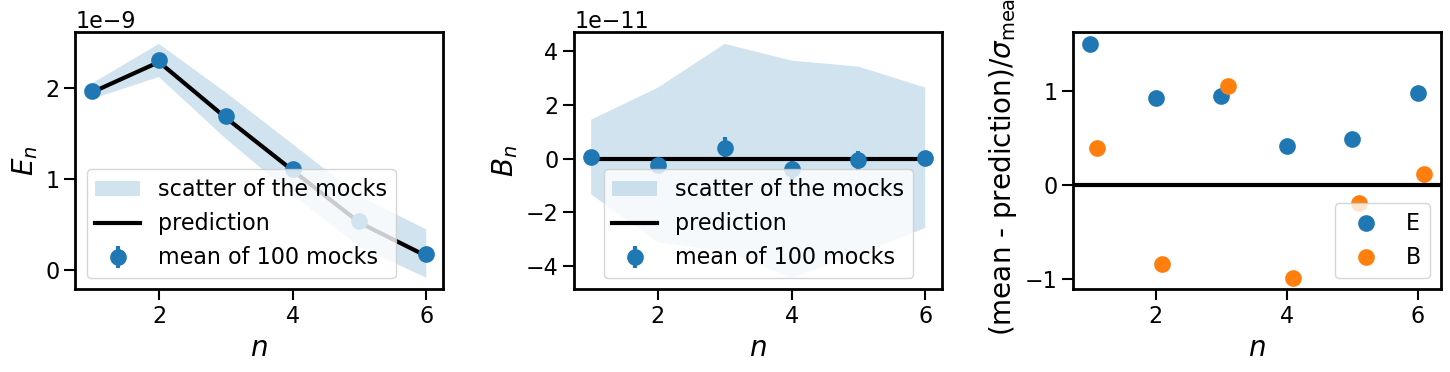

E_n: mean/prediction - 1 = [0.00655274 0.00736447 0.01426918 0.01043766 0.02589258 0.16538003]


In [10]:
def mean_and_errors(realisations):
    """
    Mean over the realisations, the scatter of a single realisation and the
    error of the mean.
    """
    scatter = np.std(realisations, axis=0, ddof=1)
    return np.mean(realisations, axis=0), scatter, scatter/np.sqrt(len(realisations))


modes = np.arange(1, n_modes + 1)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, sim, theory, label in ((axes[0], En, En_theory, 'E'),
                               (axes[1], Bn, np.zeros(n_modes), 'B')):
    mean, scatter, error = mean_and_errors(sim)
    ax.fill_between(modes, mean - scatter, mean + scatter, alpha=.2,
                    label='scatter of the mocks')
    ax.errorbar(modes, mean, error, fmt='o', label='mean of %i mocks' % len(sim))
    ax.plot(modes, theory, 'k-', label='prediction')
    ax.set_xlabel(r'$n$')
    ax.set_ylabel(r'$%s_n$' % label)
    ax.legend()
for shift, sim, theory, label in ((0, En, En_theory, 'E'), (.1, Bn, 0, 'B')):
    mean, _, error = mean_and_errors(sim)
    axes[2].plot(modes + shift, (mean - theory)/error, 'o', label=label)
axes[2].axhline(0, color='k')
axes[2].set_xlabel(r'$n$')
axes[2].set_ylabel(r'(mean - prediction)/$\sigma_{\rm mean}$')
axes[2].legend()
plt.tight_layout()
plt.show()
print('E_n: mean/prediction - 1 =', mean_and_errors(En)[0]/En_theory - 1)

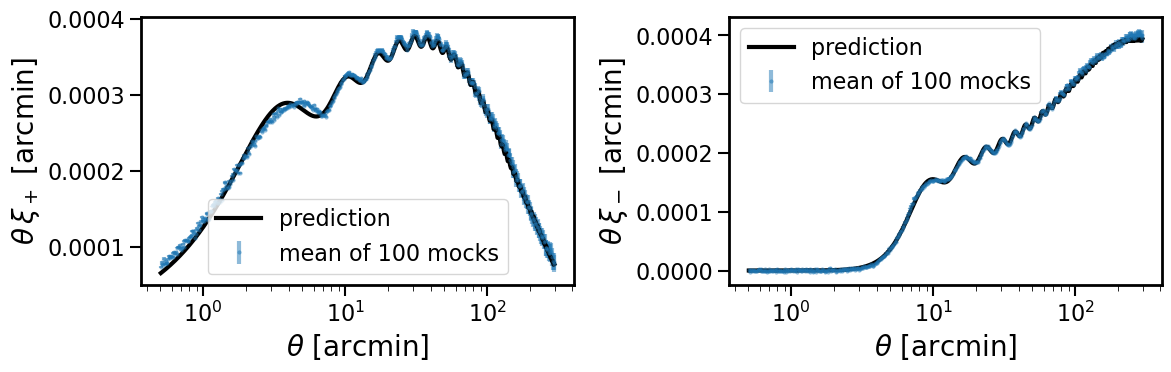

In [11]:
theta = np.sqrt(fine_edges[1:]*fine_edges[:-1])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, sim, theory, label in ((axes[0], xi_plus, xi_plus_theory, '+'),
                               (axes[1], xi_minus, xi_minus_theory, '-')):
    mean, _, error = mean_and_errors(sim)
    ax.errorbar(theta, theta*mean, theta*error, fmt='.', ms=2, alpha=.5,
                label='mean of %i mocks' % len(sim))
    ax.plot(theta, theta*theory, 'k-', label='prediction')
    ax.set_xscale('log')
    ax.set_xlabel(r'$\theta$ [arcmin]')
    ax.set_ylabel(r'$\theta\,\xi_%s$ [arcmin]' % label)
    ax.legend()
plt.tight_layout()
plt.show()